# HSA_Cam_B_010.py
This file uses the LHHW_Model of kinetics to determine kinetic parameters and an optimal next experiment.

HSA_Cam_B_006.py is the model. This uses homoscedastic noise. Additionally, most parameters are at their expected values to investigate the behavior of the KL Divergence

### Plan:
* Instantiate the model on a single proposed temperature 
* Run inference
* Check that the HDI is reasonable
* calculate the KLD for the already observed temperature and a new proposed temperature


### Results:


In [1]:
import jax.numpy as jnp
import jax
import numpy as np
import matplotlib.pyplot as plt

import pymc as pm
import pytensor

import arviz as az
from scipy.optimize import minimize

In [2]:
from HSA_Cam_B_006 import (
    SIDX,
    TRUE_PARAMS,
    _kinetics_model,
    input_p,
    bmodel,
)

# pytensor.config.mode = "JAX"

In [3]:
def post_model_over_T(proposal, idata, key="posterior"):

    test_params = {
        "p_i": input_p(
            jnp.array(proposal[1]).reshape(1, 1),
            jnp.array(proposal[2]).reshape(1, 1),
            jnp.array(proposal[3]).reshape(1, 1),
            jnp.array(proposal[4]).reshape(1, 1),
        ).reshape(1, -1),
        "T": jnp.linspace(500.0, 600.0, 100).reshape(-1, 1),
        "k0": idata[key]["k0"].values.reshape(1, -1),
        "Ea_k": idata[key]["Ea_k"].values.reshape(1, -1),
        "A_oh": idata[key]["A_oh"].values.reshape(1, -1),
        "dH_oh": idata[key]["dH_oh"].values.reshape(1, -1),
        "A_h2": idata[key]["A_h2"].values.reshape(1, -1),
        "dH_h2": idata[key]["dH_h2"].values.reshape(1, -1),
        "A_mix": idata[key]["A_mix"].values.reshape(1, -1),
        "dH_mix": idata[key]["dH_mix"].values.reshape(1, -1),
    }

    test_res = _kinetics_model(**test_params)
    return test_res


def true_model_over_T(proposal):
    true_res_T = _kinetics_model(
        input_p(
            jnp.array(proposal[1]).reshape(1, 1),
            jnp.array(proposal[2]).reshape(1, 1),
            jnp.array(proposal[3]).reshape(1, 1),
            jnp.array(proposal[4]).reshape(1, 1),
        ).reshape(1, -1),
        jnp.linspace(500.0, 600.0, 100).reshape(-1, 1),
        *TRUE_PARAMS.values(),
    )
    return true_res_T

In [4]:
def post_model_at_proposal(proposal, idata, key="posterior", n_samples=5):

    param_samples = az.extract(idata, group=key, num_samples=n_samples)

    test_params = {
        "p_i": input_p(
            jnp.array(proposal[1]).reshape(1, 1),
            jnp.array(proposal[2]).reshape(1, 1),
            jnp.array(proposal[3]).reshape(1, 1),
            jnp.array(proposal[4]).reshape(1, 1),
        ).reshape(1, -1),
        "T": jnp.array(proposal[0]).reshape(1, 1),
        "k0": param_samples["k0"].values.reshape(1, -1),
        "Ea_k": param_samples["Ea_k"].values.reshape(1, -1),
        "A_oh": param_samples["A_oh"].values.reshape(1, -1),
        "dH_oh": param_samples["dH_oh"].values.reshape(1, -1),
        "A_h2": param_samples["A_h2"].values.reshape(1, -1),
        "dH_h2": param_samples["dH_h2"].values.reshape(1, -1),
        "A_mix": param_samples["A_mix"].values.reshape(1, -1),
        "dH_mix": param_samples["dH_mix"].values.reshape(1, -1),
    }

    r = _kinetics_model(**test_params)
    obs_r = r + jax.random.normal(jax.random.PRNGKey(1), r.shape) * 1e-5
    return obs_r

In [5]:
def plot_post_model_at_proposal(proposal, test_res, true_res, Ts):
    plt.plot(
        Ts,
        test_res.mean(axis=1),
    )
    plt.plot(
        Ts,
        true_res.squeeze(),
        color="black",
        linestyle="--",
    )
    plt.fill_between(
        x=Ts,
        y1=np.percentile(test_res, 2.5, axis=1),
        y2=np.percentile(test_res, 97.5, axis=1),
        alpha=0.3,
        zorder=0,
    )
    ax = plt.gca()
    ax.text(
        0.05,
        0.95,
        f"pred. @ p={proposal[1]:.2f}, F= {proposal[2]:.2f}, C= {proposal[3]:.2f}, H2= {proposal[4]:.2f}",
        transform=ax.transAxes,
        fontsize=10,
    )
    ax2 = ax.twinx()
    ax2.plot(
        Ts,
        (np.percentile(test_res, 97.5, axis=1) - np.percentile(test_res, 2.5, axis=1))
        / np.mean(test_res, axis=1),
        color="orange",
    )

In [6]:
def observe_at_proposal(proposals):
    T = jnp.array([proposals[:, 0]], dtype=jnp.float32).reshape(-1, 1)
    p = jnp.array([proposals[:, 1]], dtype=jnp.float32).reshape(-1, 1)
    c2h = jnp.array([proposals[:, 2]], dtype=jnp.float32).reshape(-1, 1)
    f = jnp.array([proposals[:, 3]], dtype=jnp.float32).reshape(-1, 1)
    c2i = jnp.array([proposals[:, 4]], dtype=jnp.float32).reshape(-1, 1)

    p_i = input_p(p, c2h, f, c2i)

    r = _kinetics_model(p_i, T, *TRUE_PARAMS.values())
    r_obs = r + jax.random.normal(jax.random.PRNGKey(1), r.shape) * 1e-5
    return T, p, c2h, f, c2i, r_obs

In [7]:
def max_func(x, idata, key="posterior"):
    T = x[0].reshape(1, 1)
    p = x[1].reshape(1, 1)
    c2h = x[2].reshape(1, 1)
    f = x[3].reshape(1, 1)
    c2i = x[4].reshape(1, 1)
    p_i = input_p(p, c2h, f, c2i)
    res = _kinetics_model(
        p_i,
        T,
        idata[key]["k0"].values.reshape(1, -1),
        idata[key]["Ea_k"].values.reshape(1, -1),
        idata[key]["A_oh"].values.reshape(1, -1),
        idata[key]["dH_oh"].values.reshape(1, -1),
        idata[key]["A_h2"].values.reshape(1, -1),
        idata[key]["dH_h2"].values.reshape(1, -1),
        idata[key]["A_mix"].values.reshape(1, -1),
        idata[key]["dH_mix"].values.reshape(1, -1),
    )
    HDI = jnp.percentile(res, 97.5) - jnp.percentile(res, 2.5)
    return -HDI

In [8]:
def detect_transformed_keys(model: pm.Model) -> dict[str, str]:
    """
    Inspect model.initial_point() to find whether a variable uses a transformed name.
    Returns mapping constrained_name -> key_expected_by_compiled_logp.
    Heuristics cover common transforms: log (-> name_log__), logit (-> name_interval__),
    but in general we fall back to the same name if present.
    """
    init = model.initial_point()
    mapping = {}
    for name in model.named_vars:
        constrained = name
        if constrained in init:
            mapping[constrained] = constrained
        elif f"{constrained}_log__" in init:
            mapping[constrained] = f"{constrained}_log__"
        elif f"{constrained}_interval__" in init:
            mapping[constrained] = f"{constrained}_interval__"
        else:
            # fallback: try to find any init key that contains the var name
            found = [k for k in init.keys() if k.startswith(constrained)]
            mapping[constrained] = found[0] if found else constrained
    return mapping


def build_point(mapping: dict[str, str], sample_dict):
    """
    Given a mapping constrained->compiled_key and a sample of constrained vars (sample_dict),
    return a point dict suitable for compiled_logp. For common transforms we apply inverse transform:
      - If compiled_key endswith '_log__' -> pass np.log(value)
      - If compiled_key endswith '_interval__' -> pass logit(value) = log(p/(1-p))
    Otherwise pass the raw constrained value.
    """

    def safe_log(x):
        return np.log(np.maximum(x, 1e-300))

    def safe_logit(x):
        x = np.clip(x, 1e-12, 1 - 1e-12)
        return np.log(x / (1 - x))

    point = {}
    for constrained_name, compiled_key in mapping.items():
        if constrained_name not in sample_dict:
            continue  # maybe a deterministic / not in sample
        val = sample_dict[constrained_name]
        if compiled_key.endswith("_log__"):
            point[compiled_key] = safe_log(val)
        elif compiled_key.endswith("_interval__"):
            point[compiled_key] = safe_logit(val)
        else:
            point[compiled_key] = val
    return point

In [9]:
def KL_divergence(model, x, y, x_new, idata, key="posterior", n_hyp_samples=5):
    """
    Compute KL divergence between posterior distributions before and after adding hypothetical data.

    KL(P_new || P_old) = E_P_new[log P_new(θ) - log P_old(θ)]

    Args:
        model: Original PyMC model
        x: Current experimental conditions
        y: Current observations
        x_new: New experimental condition to test
        idata: Current posterior samples
        key: Which group to use from idata ("posterior" or "prior")
        n_hyp_samples: Number of hypothetical observations to average over

    Returns:
        Average KL divergence across hypothetical samples
    """

    # Step 1: Generate hypothetical observations at the new experimental condition
    y_new_samples = post_model_at_proposal(
        x_new, idata, key=key, n_samples=n_hyp_samples
    ).reshape(-1, 1)
    # y_new_samples = az.extract(
    #     idata,
    #     group=key,
    #     var_names=["y_hat"],
    #     num_samples=n_hyp_samples,
    # ).values.reshape(-1, 1)
    print(f"Generated {n_hyp_samples} hypothetical observations at new condition")

    # Step 2: Compute KL divergence for each hypothetical observation
    kl_values = []

    for i in range(n_hyp_samples):
        print(f"Processing hypothetical sample {i+1}/{n_hyp_samples}")

        # Get the i-th hypothetical observation
        y_hyp = y_new_samples[i].reshape(1, 1)

        # Create augmented dataset: combine current data with hypothetical observation
        x_augmented = jnp.vstack([x, x_new.reshape(1, -1)])
        y_augmented = jnp.vstack([y, y_hyp])

        # Build new model with augmented data
        T_aug, p_aug, c2h_aug, f_aug, c2i_aug, _ = observe_at_proposal(x_augmented)
        model_new = bmodel(
            (
                np.asarray(T_aug),
                np.asarray(p_aug),
                np.asarray(c2h_aug),
                np.asarray(f_aug),
                np.asarray(c2i_aug),
            ),
            np.asarray(y_augmented),
        )
        # Detect transformed variable keys for logp evaluation
        old_transform_mapping = detect_transformed_keys(model)
        new_transform_mapping = detect_transformed_keys(model_new)

        # Sample from the new posterior (with augmented data)
        with model_new:
            # Use fewer samples for speed, but ensure convergence
            idata_new = pm.sample(
                tune=1000,
                draws=4000,
                target_accept=0.9,
                return_inferencedata=True,
                progressbar=False,  # Reduce output clutter
            )

        # Step 3: Compute log probabilities for KL divergence
        # Extract parameter samples from both posteriors
        old_samples = az.extract(
            idata,
            group=key,
            num_samples=500,
            var_names=[
                "Ea_k",
                "k0",
                "dH_oh",
                "dH_h2",
                "dH_mix",
                "A_oh",
                "A_h2",
                "A_mix",
                "sigma_r",
                # "~y_hat",
            ],
        )
        new_samples = az.extract(
            idata_new,
            group="posterior",
            num_samples=500,
            var_names=[
                "Ea_k",
                "k0",
                "dH_oh",
                "dH_h2",
                "dH_mix",
                "A_oh",
                "A_h2",
                "A_mix",
                "sigma_r",
                # "~y_hat",
            ],
        )
        post_dict = {}
        for var in new_samples.data_vars:
            post_dict[var] = new_samples[var].values

        # Compile log probability functions
        old_logp = model.compile_logp()
        new_logp = model_new.compile_logp()

        # Compute KL divergence: E_new[log P_new(θ) - log P_old(θ)]
        log_ratios = []

        for j in range(min(500, len(new_samples.chain))):
            # Get parameter values from new posterior sample using helper function
            sample_dict = {k: v[j] for k, v in post_dict.items()}

            # Build points for both models using their respective transformations
            new_point = build_point(new_transform_mapping, sample_dict)
            old_point = build_point(old_transform_mapping, sample_dict)

            try:
                # Evaluate log probabilities at the same parameter values
                # but using the correct transformations for each model
                logp_new = new_logp(new_point)
                logp_old = old_logp(old_point)

                # Add to KL divergence calculation
                log_ratios.append(logp_new - logp_old)

            except Exception as e:
                # Skip problematic points (can happen due to parameter transformations)
                print(f"    Skipping sample {j}: {str(e)}")
                continue

        # Compute KL divergence for this hypothetical sample
        if log_ratios:
            kl_i = np.mean(log_ratios)
            kl_values.append(kl_i)
            # Debug: print some statistics about the log ratios
            print(f"  KL divergence for sample {i+1}: {kl_i:.4f}")
            print(
                f"    Log ratio stats: mean={np.mean(log_ratios):.2f}, std={np.std(log_ratios):.2f}"
            )
            print(
                f"    Min/Max log ratios: {np.min(log_ratios):.2f} / {np.max(log_ratios):.2f}"
            )
        else:
            print(f"  Warning: No valid log probability evaluations for sample {i+1}")

    # Step 4: Return average KL divergence across all hypothetical samples
    if kl_values:
        avg_kl = np.mean(kl_values)
        print(f"Average KL divergence: {avg_kl:.4f}")
        return avg_kl
    else:
        print("Error: No valid KL divergence values computed")
        return np.nan

generate the first 4 points on purpose

In [10]:
proposals = np.array(
    [
        [555.0, 4.0, 0.5, 1000.0, 0.5],
        [555.0, 20.0, 0.5, 1000.0, 0.5],
        # [580.0, 4.0, 0.5, 1000.0, 0.5],
    ]
)

In [11]:
T, p, c2h, f, c2i, r_obs = observe_at_proposal(proposals)
model = bmodel(
    (
        np.asarray(T),
        np.asarray(p),
        np.asarray(c2h),
        np.asarray(f),
        np.asarray(c2i),
    ),
    np.asarray(r_obs),
)
with model:
    prior_idata = pm.sample_prior_predictive(samples=1000)
    idata = pm.sample(
        tune=1000,
        draws=4000,
        chains=4,
        target_accept=0.9,
        return_inferencedata=True,
    )
    logp_fun = model.compile_logp()

Sampling: [A_h2, A_mix, A_oh, Ea_k, LH2, dH_h2, dH_mix, dH_oh, k0, sigma_r]
Initializing NUTS using jitter+adapt_diag...
c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\pytensor\link\c\cmodule.py:2968: UserWarning: PyTensor could not link to a BLAS installation. Operations that might benefit from BLAS will be severely degraded.
This usually happens when PyTensor is installed via pip. We recommend it be installed via conda/mamba/pixi instead.
Alternatively, you can use an experimental backend such as Numba or JAX that perform their own BLAS optimizations, by setting `pytensor.config.mode == 'NUMBA'` or passing `mode='NUMBA'` when compiling a PyTensor function.
For more options and details see https://pytensor.readthedocs.io/en/latest/troubleshooting.html#how-do-i-configure-test-my-blas-library
  warnings.warn(
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [k0, Ea_k, A_oh, dH_oh, A_h2, dH_h2, A_mix, dH_mix, sigma_r]


Output()

Sampling 4 chains for 1_000 tune and 4_000 draw iterations (4_000 + 16_000 draws total) took 42 seconds.


In [12]:
idata.prior = prior_idata.prior

array([[<Axes: >, <Axes: >, <Axes: xlabel='dH_mix'>],
       [<Axes: >, <Axes: >, <Axes: xlabel='dH_oh'>],
       [<Axes: >, <Axes: >, <Axes: xlabel='A_h2'>],
       [<Axes: >, <Axes: >, <Axes: xlabel='A_mix'>],
       [<Axes: >, <Axes: >, <Axes: xlabel='Ea_k'>],
       [<Axes: >, <Axes: >, <Axes: xlabel='k0'>],
       [<Axes: >, <Axes: >, <Axes: xlabel='dH_h2'>],
       [<Axes: >, <Axes: >, <Axes: xlabel='sigma_r'>],
       [<Axes: >, <Axes: >, <Axes: xlabel='A_oh'>],
       [<Axes: >, <Axes: >, <Axes: xlabel='y_hat\n0, 0'>],
       [<Axes: >, <Axes: >, <Axes: xlabel='y_hat\n1, 0'>]], dtype=object)



In [13]:
import ICIW_Plots

plt.style.use("ICIWstyle")
az.plot_dist_comparison(
    idata,
    # var_names=["Ea_k"],
    # figsize=(7, 5),
)

In [14]:
az.summary(
    idata,
    var_names=[
        "Ea_k",
        "k0",
        "dH_oh",
        "dH_h2",
        "dH_mix",
        "A_oh",
        "A_h2",
        "A_mix",
        "sigma_r",
    ],
    group="posterior",
)

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
Ea_k,59711.857,58839.132,18.064,166368.624,376.959,749.845,19038.0,8784.0,1.0
k0,0.000,0.000,0.000,0.000,0.000,0.000,28451.0,11471.0,1.0
dH_oh,22400.000,1.009,22398.069,22401.832,0.006,0.009,24613.0,11894.0,1.0
dH_h2,-6200.011,1.007,-6201.953,-6198.177,0.007,0.008,20982.0,12675.0,1.0
dH_mix,-9999.994,1.006,-10001.944,-9998.181,0.007,0.008,23525.0,12708.0,1.0
A_oh,0.500,0.010,0.481,0.519,0.000,0.000,22218.0,12295.0,1.0
A_h2,0.443,0.009,0.425,0.460,0.000,0.000,23292.0,12376.0,1.0
A_mix,0.882,0.010,0.864,0.900,0.000,0.000,25505.0,13075.0,1.0
sigma_r,0.000,0.000,0.000,0.000,0.000,0.000,20221.0,11610.0,1.0


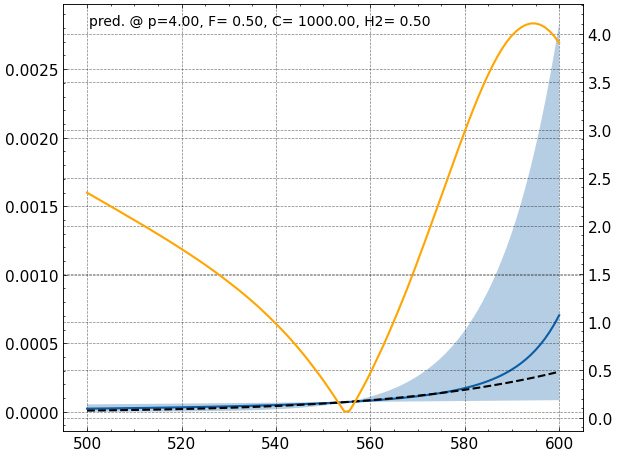

In [15]:
i = 0
Ts = jnp.linspace(500.0, 600.0, 100)
# test_res = post_model_over_T(proposals[i], prior_idata, key="prior")
r = post_model_over_T(proposals[i], idata, key="posterior")
true_res_T = true_model_over_T(proposals[i])
plot_post_model_at_proposal(proposals[i], r, true_res_T, Ts)

# Repeat with the newly added point

In [38]:
aug_proposals = np.array(
    [
        [555.0, 4.0, 0.5, 1000.0, 0.5],
        [555.0, 20.0, 0.5, 1000.0, 0.5],
        # [600.0, 4.0, 0.5, 1000.0, 0.5],
        [555.0, 4.0, 0.5, 1000.0, 0.5],
    ]
)
T_aug, p_aug, c2h_aug, f_aug, c2i_aug, r_obs_aug = observe_at_proposal(aug_proposals)
aug_model = bmodel(
    (
        np.asarray(T_aug),
        np.asarray(p_aug),
        np.asarray(c2h_aug),
        np.asarray(f_aug),
        np.asarray(c2i_aug),
    ),
    np.asarray(r_obs_aug),
)
with aug_model:
    aug_idata = pm.sample(
        tune=1000,
        draws=4000,
        chains=4,
        target_accept=0.9,
        return_inferencedata=True,
    )
aug_logp_fun = aug_model.compile_logp()

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [k0, Ea_k, A_oh, dH_oh, A_h2, dH_h2, A_mix, dH_mix, sigma_r]


Output()

Sampling 4 chains for 1_000 tune and 4_000 draw iterations (4_000 + 16_000 draws total) took 45 seconds.


In [39]:
print(r_obs_aug)

[[8.08347396e-05]
 [1.12348823e-04]
 [8.13323321e-05]]


In [40]:
aug_idata.prior = prior_idata.prior

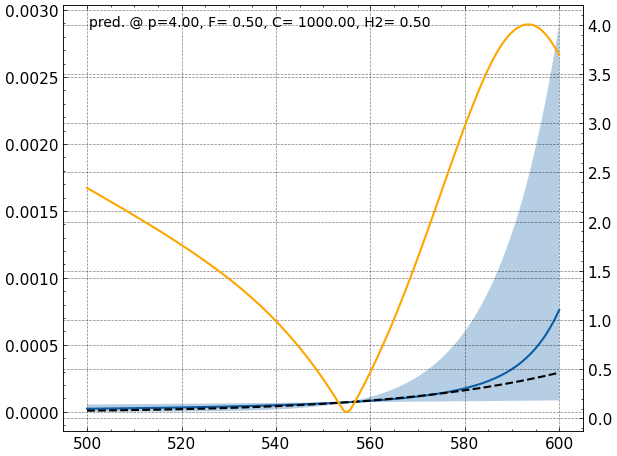

In [41]:
i = 0
Ts = jnp.linspace(500.0, 600.0, 100)
# test_res = post_model_over_T(proposals[i], prior_idata, key="prior")
r = post_model_over_T(aug_proposals[i], aug_idata, key="posterior")
true_res_T = true_model_over_T(aug_proposals[i])
plot_post_model_at_proposal(aug_proposals[i], r, true_res_T, Ts)

array([[<Axes: >, <Axes: >, <Axes: xlabel='Ea_k'>],
       [<Axes: >, <Axes: >, <Axes: xlabel='k0'>],
       [<Axes: >, <Axes: >, <Axes: xlabel='dH_oh'>],
       [<Axes: >, <Axes: >, <Axes: xlabel='dH_h2'>],
       [<Axes: >, <Axes: >, <Axes: xlabel='dH_mix'>],
       [<Axes: >, <Axes: >, <Axes: xlabel='A_oh'>],
       [<Axes: >, <Axes: >, <Axes: xlabel='A_h2'>],
       [<Axes: >, <Axes: >, <Axes: xlabel='A_mix'>],
       [<Axes: >, <Axes: >, <Axes: xlabel='sigma_r'>]], dtype=object)

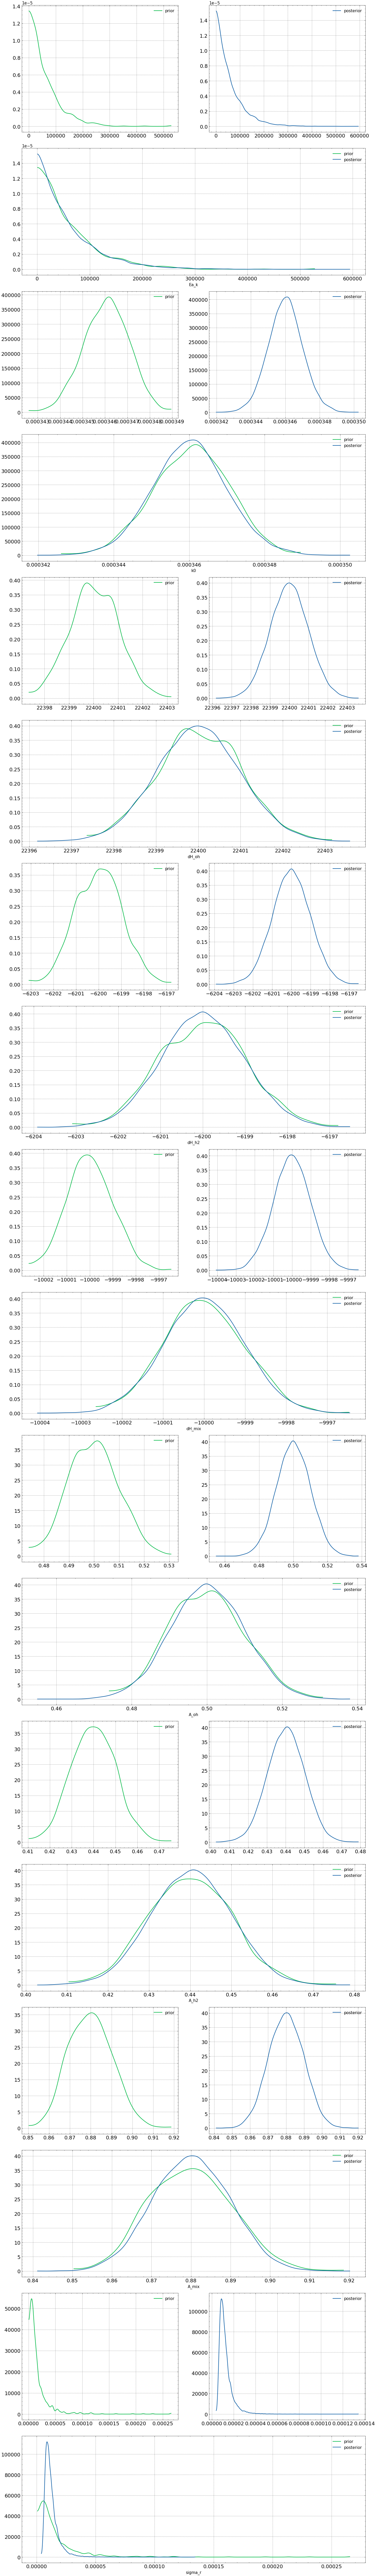

In [42]:
az.plot_dist_comparison(
    aug_idata,
    var_names=[
        "Ea_k",
        "k0",
        "dH_oh",
        "dH_h2",
        "dH_mix",
        "A_oh",
        "A_h2",
        "A_mix",
        "sigma_r",
    ],
)

In [43]:
az.summary(
    aug_idata,
    var_names=[
        "Ea_k",
        "k0",
        "dH_oh",
        "dH_h2",
        "dH_mix",
        "A_oh",
        "A_h2",
        "A_mix",
        "sigma_r",
    ],
    group="posterior",
)

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
Ea_k,60107.775,59722.502,6.154,167345.054,383.903,737.370,18792.0,9191.0,1.0
k0,0.000,0.000,0.000,0.000,0.000,0.000,28955.0,11166.0,1.0
dH_oh,22399.999,0.993,22398.104,22401.824,0.006,0.009,30695.0,11697.0,1.0
dH_h2,-6200.009,0.984,-6201.821,-6198.130,0.006,0.009,31457.0,11270.0,1.0
dH_mix,-10000.002,0.987,-10001.832,-9998.110,0.006,0.009,31316.0,11639.0,1.0
A_oh,0.500,0.010,0.481,0.518,0.000,0.000,28459.0,11976.0,1.0
A_h2,0.440,0.010,0.423,0.459,0.000,0.000,27760.0,12148.0,1.0
A_mix,0.880,0.010,0.862,0.898,0.000,0.000,25803.0,11895.0,1.0
sigma_r,0.000,0.000,0.000,0.000,0.000,0.000,23322.0,9996.0,1.0


### measure the divergence between the two distributions

In [31]:
new_samples = az.extract(
    aug_idata,
    group="posterior",
    num_samples=4000,
    var_names=[
        "Ea_k",
        "k0",
        "dH_oh",
        "dH_h2",
        "dH_mix",
        "A_oh",
        "A_h2",
        "A_mix",
        "sigma_r",
        # "~y_hat",
    ],
    # var_names=["Ea_k"],
)
post_dict = {}
for var in new_samples.data_vars:
    post_dict[var] = new_samples[var].values

# post_dict = {"Ea_k": new_samples.values}

transform_mapping = detect_transformed_keys(aug_model)

In [32]:
KLDs = []
for i in range(4000):
    param_dict = {k: v[i] for k, v in post_dict.items()}
    point = build_point(transform_mapping, param_dict)
    ### measure the divergence between the two distributions
    logp_old = logp_fun(point)
    logp_new = aug_logp_fun(point)
    divergence = logp_new - logp_old
    KLDs.append(divergence)
    # print(f"Divergence for sample {i}: {divergence}")
KLDs = np.array(KLDs)
print(f"Average KL Divergence: {KLDs.mean()}")
print(f"Std of KL Divergence: {KLDs.std()}")

Average KL Divergence: 9.03950200931299
Std of KL Divergence: 0.862714931103327


### Intermediate result:
The difference in KLD is marginal. This is becasue the KLD basically only measures the divergence in the sigma parameter, which has much higher density than the other parameters. It is a scaling issue.
KL divergence for continuous distributions is:

DKL(P∥Q)=∫P(θ)log⁡P(θ)Q(θ) dθ
D
KL
	​

(P∥Q)=∫P(θ)log
Q(θ)
P(θ)
	​

dθ

If 
P(θ)
P(θ) is very narrow, its density can be huge (e.g., 
P(θ)≈105
P(θ)≈10
5
) at the peak.

The log-density 
log⁡P(θ)
logP(θ) is correspondingly large (
∼12
∼12 in this example).

When you compute the KL, the narrow peak dominates the integral, even if other dimensions or broader distributions change a lot.

### Another Idea: calculate the KLD for each parameter individually and sum them up normalized by their variance

In [44]:
from scipy.stats import gaussian_kde
from scipy.integrate import simpson


def kl_marginal(P_samples, Q_samples, eps=1e-12):
    print(P_samples.shape, Q_samples.shape)
    kde_P = gaussian_kde(P_samples)
    kde_Q = gaussian_kde(Q_samples)

    grid = np.linspace(
        min(P_samples.min(), Q_samples.min()),
        max(P_samples.max(), Q_samples.max()),
        1000,
    )

    p_vals = kde_P(grid) + eps
    q_vals = kde_Q(grid) + eps

    kld = simpson(p_vals * np.log(p_vals / q_vals), grid)
    return kld


# Compute KL per parameter
old_samples = az.extract(
    idata,
    group="posterior",
    var_names=["~y_hat"],
    num_samples=1000,
)
old_post_dict = {}
for var in old_samples.data_vars:
    old_post_dict[var] = old_samples[var].values

new_samples = az.extract(
    aug_idata,
    group="posterior",
    var_names=["~y_hat"],
    num_samples=1000,
)

post_dict = {}
for var in new_samples.data_vars:
    post_dict[var] = new_samples[var].values

kl_per_param = {}
for param_name, draws in post_dict.items():
    print(f"Computing KL for parameter: {param_name}")
    kl = kl_marginal(draws, old_post_dict[param_name])
    kl_per_param[param_name] = kl

print("KL Divergence per parameter:")
for param, kl_value in kl_per_param.items():
    print(f"  {param}: {kl_value:.4f}")

Computing KL for parameter: k0
(1000,) (1000,)
Computing KL for parameter: A_oh
(1000,) (1000,)
Computing KL for parameter: dH_oh
(1000,) (1000,)
Computing KL for parameter: A_h2
(1000,) (1000,)
Computing KL for parameter: dH_h2
(1000,) (1000,)
Computing KL for parameter: A_mix
(1000,) (1000,)
Computing KL for parameter: dH_mix
(1000,) (1000,)
Computing KL for parameter: Ea_k
(1000,) (1000,)
Computing KL for parameter: sigma_r
(1000,) (1000,)
KL Divergence per parameter:
  k0: 0.0041
  A_oh: 0.0043
  dH_oh: 0.0095
  A_h2: 0.0617
  dH_h2: 0.0073
  A_mix: 0.0238
  dH_mix: 0.0157
  Ea_k: 0.0273
  sigma_r: 0.8539


### This works!

## test the KL divergence calculation

In [24]:
new_proposal = jnp.array(
    [580.0, 4.0, 0.5, 1000.0, 0.5],
)
KL_divergence(
    aug_model,
    aug_proposals[:, :],
    r_obs,
    new_proposal.squeeze(),
    idata,
    key="posterior",
    n_hyp_samples=5,
)

Generated 5 hypothetical observations at new condition
Processing hypothetical sample 1/5


Initializing NUTS using jitter+adapt_diag...


ValueError: Input dimension mismatch: (input[%i].shape[%i] = %lld, input[%i].shape[%i] = %lld)
Apply node that caused the error: Composite{...}(LH2{[[7.298857 ... 9470e-04]]}, kinOp.0, ExpandDims{axes=[0, 1]}.0, Log.0, Gt.0)
Toposort index: 21
Inputs types: [TensorType(float64, shape=(3, 1)), TensorType(float64, shape=(None, None)), TensorType(float64, shape=(1, 1)), TensorType(float64, shape=(1, 1)), TensorType(bool, shape=(1, 1))]
Inputs shapes: [(3, 1), (4, 1), (1, 1), (1, 1), (1, 1)]
Inputs strides: [(8, 8), (8, 8), (8, 8), (8, 8), (1, 1)]
Inputs values: [array([[7.29885706e-05],
       [1.17439695e-04],
       [1.31649470e-04]]), array([[-0.06823482],
       [-0.09692116],
       [-0.06823482],
       [-0.13071521]]), array([[1.17578558e-05]]), array([[-11.35098896]]), array([[ True]])]
Outputs clients: [[Sum{axes=None}(Composite{...}.0)], [VJPkinOp([[7.998400 ... 8007e+00]], [[555.] [5 ... .] [580.]], Subtensor{i}.0, Composite{...}.0, Subtensor{i}.0, Subtensor{i}.0, Subtensor{i}.0, Subtensor{i}.0, Subtensor{i}.0, Subtensor{i}.0, Composite{...}.1)], [Sum{axes=None}(sigma > 0)]]

HINT: Re-running with most PyTensor optimizations disabled could provide a back-trace showing when this node was created. This can be done by setting the PyTensor flag 'optimizer=fast_compile'. If that does not work, PyTensor optimizations can be disabled with 'optimizer=None'.
HINT: Use the PyTensor flag `exception_verbosity=high` for a debug print-out and storage map footprint of this Apply node.

In [ ]:
new_proposal = jnp.array(
    [555.0, 4.0, 0.5, 1000.0, 0.5],
)
KL_divergence(
    aug_model,
    aug_proposals[:, :],
    r_obs,
    new_proposal.squeeze(),
    idata,
    key="posterior",
    n_hyp_samples=5,
)

Generated 5 hypothetical observations at new condition
Processing hypothetical sample 1/5


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [k0, Ea_k, A_oh, dH_oh, A_h2, dH_h2, A_mix, dH_mix, sigma_r]
Sampling 4 chains for 1_000 tune and 4_000 draw iterations (4_000 + 16_000 draws total) took 42 seconds.


  KL divergence for sample 1: 10.3452
    Log ratio stats: mean=10.35, std=0.43
    Min/Max log ratios: 6.08 / 11.03
Processing hypothetical sample 2/5


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [k0, Ea_k, A_oh, dH_oh, A_h2, dH_h2, A_mix, dH_mix, sigma_r]
Sampling 4 chains for 1_000 tune and 4_000 draw iterations (4_000 + 16_000 draws total) took 42 seconds.


  KL divergence for sample 2: 10.5361
    Log ratio stats: mean=10.54, std=0.41
    Min/Max log ratios: 7.70 / 11.27
Processing hypothetical sample 3/5


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [k0, Ea_k, A_oh, dH_oh, A_h2, dH_h2, A_mix, dH_mix, sigma_r]
Sampling 4 chains for 1_000 tune and 4_000 draw iterations (4_000 + 16_000 draws total) took 42 seconds.


  KL divergence for sample 3: 9.5792
    Log ratio stats: mean=9.58, std=0.66
    Min/Max log ratios: 3.41 / 10.27
Processing hypothetical sample 4/5


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [k0, Ea_k, A_oh, dH_oh, A_h2, dH_h2, A_mix, dH_mix, sigma_r]
Sampling 4 chains for 1_000 tune and 4_000 draw iterations (4_000 + 16_000 draws total) took 39 seconds.
There was 1 divergence after tuning. Increase `target_accept` or reparameterize.


  KL divergence for sample 4: 11.2486
    Log ratio stats: mean=11.25, std=0.38
    Min/Max log ratios: 9.74 / 12.06
Processing hypothetical sample 5/5


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [k0, Ea_k, A_oh, dH_oh, A_h2, dH_h2, A_mix, dH_mix, sigma_r]
Sampling 4 chains for 1_000 tune and 4_000 draw iterations (4_000 + 16_000 draws total) took 39 seconds.


  KL divergence for sample 5: 11.4088
    Log ratio stats: mean=11.41, std=0.49
    Min/Max log ratios: 9.75 / 12.61
Average KL divergence: 10.6236


np.float64(10.623576825766072)